In [166]:
import torch
import torch.nn as nn
import json
import matplotlib.pyplot as plt
from tqdm import tqdm
from torch.utils.data import Dataset, DataLoader

In [167]:
# device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
device = "cpu"
print(device)

cpu


In [168]:
batch_size = 1024
learning_rate = 3e-4
num_epochs = 10

In [169]:
with open('train_data.json', 'r', encoding='utf-8') as f:
    train_data = json.load(f)

with open('val_data.json', 'r', encoding='utf-8') as f:
    val_data = json.load(f)

# with open('test_data.json', 'r', encoding='utf-8') as f:
#     test_data = json.load(f)


class CropDataset(Dataset):

    def __init__(self, split='train'):
        self.samples = []

        if split == 'train':
            data = train_data
        elif split == 'val':
            data = val_data
        # elif split == 'test':
        #     data = test_data

        for path_to_img, crops in data.items():
            for crop in crops:
                x = torch.tensor(crop["x"], dtype=torch.float32)
                y = torch.tensor(crop["y"], dtype=torch.float32)
                self.samples.append((x, y))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        x, y = self.samples[idx]
        return x.to(device), y.to(device)
    

train_dataset = CropDataset(split='train')
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

val_dataset = CropDataset(split='val')
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

# test_dataset = CropDataset(split='test')
# test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

In [170]:
class NeuralNetwork(torch.nn.Module):

    def __init__(self):
        super().__init__()
        self.layer1 = nn.Sequential(
            nn.Linear(7*4, 64),
            nn.BatchNorm1d(64),
            nn.ReLU()
        )
        self.layer2 = nn.Sequential(
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU()
        )
        self.layer3 = nn.Sequential(
            nn.Linear(32, 1)
        )

    def forward(self, x):
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        return x

In [177]:
model = NeuralNetwork().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
criterion = nn.BCEWithLogitsLoss()

train_loss_list, val_loss_list = [], []
train_acc_loss, val_acc_loss = [], []

In [178]:
def get_accuracy(split="train"):

    if split == "train":
        loader = train_loader
    elif split == "val":
        loader = val_loader
    # elif split == "test":
    #     loader = test_loader

    total = 0
    correct = 0
    model.eval()
    with torch.no_grad():
        for x, y in loader:
            total += y.shape[0]
            y_pred = torch.sigmoid(model(x))
            sampled = torch.bernoulli(y_pred)
            correct += (sampled.view(-1) == y.view(-1)).float().sum().item()
    accuracy = correct / total
    model.train()

    return accuracy

100%|██████████| 445/445 [00:03<00:00, 136.10it/s]


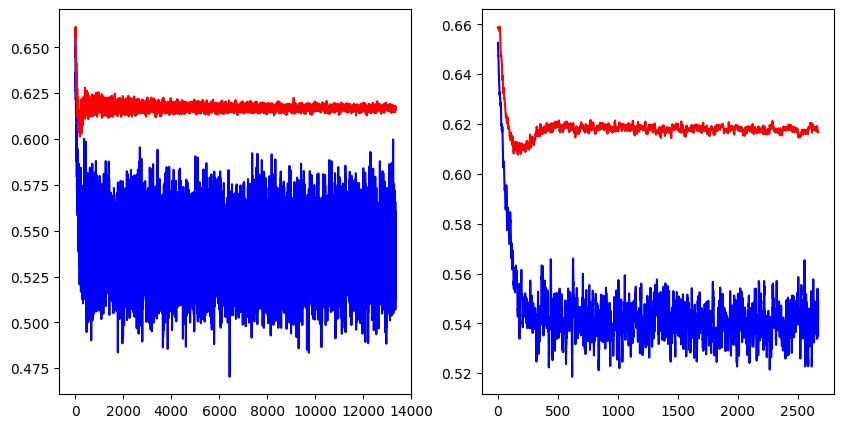

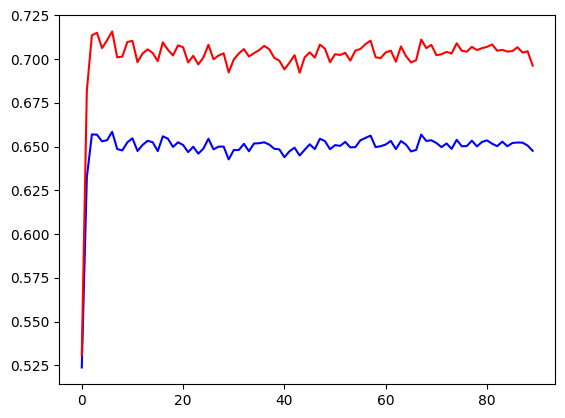

In [181]:
for n_epoch in range(num_epochs):

    for i, (x, y) in tqdm(enumerate(train_loader), total=len(train_loader)):

        x = torch.randint(0, 2, x.shape, dtype=torch.float32).to(device)

        y_pred = model(x)

        loss = criterion(y_pred.view(-1), y)
            
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()


        # loss
        if i % 1 == 0:
            train_loss_list.append(loss.item())
            model.eval()
            with torch.no_grad():
                x, y = next(iter(val_loader))
                x = torch.randint(0, 2, x.shape, dtype=torch.float32).to(device)
                y_pred = model(x)
                val_loss = criterion(y_pred.view(-1), y)
                val_loss_list.append(val_loss.item())
            model.train()

        # accuracy
        if i % 200 == 0:
            train_acc_loss.append(get_accuracy(split="train"))
            val_acc_loss.append(get_accuracy(split="val"))


s = 5
train_loss_list_moyennée = [sum(train_loss_list[i:i+s])/s for i in range(int(len(train_loss_list)/s))]
val_loss_list_moyennée = [sum(val_loss_list[i:i+s])/s for i in range(int(len(val_loss_list)/s))]

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.plot(train_loss_list, c='blue')
plt.plot(val_loss_list, c='red')
plt.subplot(1, 2, 2)
plt.plot(train_loss_list_moyennée, c='blue')
plt.plot(val_loss_list_moyennée, c='red')
plt.show()

plt.plot(train_acc_loss, c='blue')
plt.plot(val_acc_loss, c='red')
plt.show()


In [183]:
print(torch.sigmoid(y_pred))

tensor([[0.2338],
        [0.2206],
        [0.2291],
        ...,
        [0.2230],
        [0.2346],
        [0.2300]])
